# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

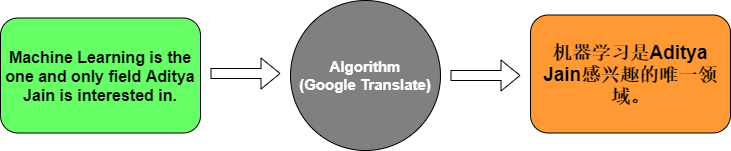

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

I0000 00:00:1793597299.176186     198 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793597299.241596     198 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793597314.230392     198 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793597322.644944     198 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them 

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


E0000 00:00:1793597326.273660     198 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.0000e+00 - loss: 2.4844 - val_accuracy: 0.0000e+00 - val_loss: 2.4895
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.5714 - loss: 2.4755 - val_accuracy: 0.0000e+00 - val_loss: 2.4916
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.5714 - loss: 2.4664 - val_accuracy: 0.0000e+00 - val_loss: 2.4938
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5714 - loss: 2.4566 - val_accuracy: 0.0000e+00 - val_loss: 2.4963
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5714 - loss: 2.4456 - val_accuracy: 0.0000e+00 - val_loss: 2.4991
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.5714 - loss: 2.4332 - val_accuracy: 0.0000e+00 - val_loss: 2.5022
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5714 - loss: 2.4187 - val_accuracy: 0.0000e+00 - val_loss: 2.5059
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5714 - loss: 2.4018 - val_accuracy: 0.0000e

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 273ms/step
Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


### Answers — Task 1

**1. What does the Embedding layer do to a word index?**
The Embedding layer converts each word index (an integer) into a dense vector of real numbers (here 64 values). Instead of treating a word as just a number, it gives the word a learned representation, so words with similar meanings end up with similar vectors.

**3. What is the role of the Encoder LSTM?**
The encoder LSTM reads the English sentence word by word and keeps track of the order and context of the words. At the end, it compresses the whole sentence into one fixed-size vector (context vector) that represents its meaning.

**5. What does the Decoder LSTM do?**
The decoder LSTM receives the context vector from the encoder (repeated for each output position by `RepeatVector`) and generates the French sentence step by step. With `return_sequences=True`, it produces one output for every position of the French sentence.

**8. Why do we use `softmax` in the final layer?**
At each position, the model must choose one word from the whole French vocabulary. Softmax turns the output scores into probabilities that add up to 1, so the word with the highest probability is selected as the translated word (using `argmax`).

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

**Note:** Download `eng_-french.csv` from the Kaggle link above and put it in the same folder as the notebook before running the cells below.

In [8]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# 1. Load the dataset (download "eng_-french.csv" from the Kaggle link and put it next to the notebook)
df = pd.read_csv("eng_-french.csv")
df.columns = ["english", "french"]
print("Dataset shape:", df.shape)
print(df.head())

# 2. Clean the data: drop missing rows, lowercase, and keep short sentences (max 8 words)
df = df.dropna()
df["english"] = df["english"].str.lower().str.strip()
df["french"] = df["french"].str.lower().str.strip()
df = df[(df["english"].str.split().str.len() <= 8) & (df["french"].str.split().str.len() <= 8)]

# Use a random sample of 20,000 pairs so the model trains in a reasonable time
df = df.sample(n=min(20000, len(df)), random_state=42).reset_index(drop=True)
print("\nNumber of sentence pairs used:", len(df))

# 3. Tokenize and pad the sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(df["english"])
eng_sequences = tokenizer_eng.texts_to_sequences(df["english"])

tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(df["french"])
frn_sequences = tokenizer_frn.texts_to_sequences(df["french"])

eng_padded = pad_sequences(eng_sequences)                   # zeros at the beginning (encoder input)
frn_padded = pad_sequences(frn_sequences, padding="post")   # zeros at the end (decoder output)

eng_vocab = len(tokenizer_eng.word_index) + 1
frn_vocab = len(tokenizer_frn.word_index) + 1
print("English vocabulary size:", eng_vocab, "| Max English length:", eng_padded.shape[1])
print("French vocabulary size:", frn_vocab, "| Max French length:", frn_padded.shape[1])

# 4. Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# 5. Build the encoder-decoder LSTM model (same structure as the lab example)
tf.random.set_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=128),
    tf.keras.layers.LSTM(256),                                   # Encoder
    tf.keras.layers.RepeatVector(frn_padded.shape[1]),
    tf.keras.layers.LSTM(256, return_sequences=True),            # Decoder
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation="softmax"))
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

# 6. Train the model
history = model.fit(eng_train, np.expand_dims(frn_train, -1),
                    epochs=20, batch_size=64, validation_split=0.1)

# 7. Evaluate the model on the test set
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Dataset shape: (175621, 2)
  english      french
0     Hi.      Salut!
1    Run!     Cours !
2    Run!    Courez !
3    Who?       Qui ?
4    Wow!  Ça alors !

Number of sentence pairs used: 20000
English vocabulary size: 5918 | Max English length: 10
French vocabulary size: 10439 | Max French length: 12


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ ?                      │   0 (unbuilt) │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 56s 235ms/step - accuracy: 0.5399 - loss: 3.8946 - val_accuracy: 0.5582 - val_loss: 3.3997
Epoch 2/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 84s 246ms/step - accuracy: 0.5578 - loss: 3.2967 - val_accuracy: 0.5591 - val_loss: 3.3096
Epoch 3/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 79s 231ms/step - accuracy: 0.5611 - loss: 3.2068 - val_accuracy: 0.5627 - val_loss: 3.2769
Epoch 4/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 53s 235ms/step - accuracy: 0.5631 - loss: 3.1603 - val_accuracy: 0.5645 - val_loss: 3.2612
Epoch 5/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 55s 242ms/step - accuracy: 0.5642 - loss: 3.1235 - val_accuracy: 0.5646 - val_loss: 3.2424
Epoch 6/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 81s 237ms/step - accuracy: 0.5649 - loss: 3.0885 - val_accuracy: 0.5651 - val_loss: 3.2296
Epoch 7/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 82s 237ms/step - accuracy: 0.5657 - loss: 3.0602 - val_accuracy: 0.5656 - val_loss: 3.2267
Epoch 8/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 52s 232ms/step - accuracy: 0.5678 - loss: 3

In [9]:
# 8. Translate English product sentences into French
def translate(sentence):
    sequence = tokenizer_eng.texts_to_sequences([sentence.lower()])
    padded = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    prediction = model.predict(padded, verbose=0)
    predicted_ids = np.argmax(prediction, axis=-1)[0]
    words = [tokenizer_frn.index_word[i] for i in predicted_ids if i != 0]
    return " ".join(words)

# Sentences from the test set (the model did not see them during training)
for i in range(5):
    english = " ".join(tokenizer_eng.index_word[w] for w in eng_test[i] if w != 0)
    reference = " ".join(tokenizer_frn.index_word[w] for w in frn_test[i] if w != 0)
    print(f"English:    {english}")
    print(f"Reference:  {reference}")
    print(f"Prediction: {translate(english)}\n")

# Short e-commerce sentences
for sentence in ["i like this shirt", "this is very expensive", "it is a good price"]:
    print(f"English: {sentence}  ->  French: {translate(sentence)}")

English:    the barber gave him a haircut
Reference:  le coiffeur lui a coupé les cheveux
Prediction: il a a à de de la

English:    i like to wear wooden clogs
Reference:  j'aime porter des sabots en bois
Prediction: je vous que de de de

English:    who died
Reference:  qui est mort
Prediction: c'est un

English:    i don't like profanity
Reference:  je n'aime pas les obscénités
Prediction: je ne pas pas

English:    i've heard about you
Reference:  j'ai entendu parler de vous
Prediction: je vous vous de

English: i like this shirt  ->  French: je vous un
English: this is very expensive  ->  French: c'est un très
English: it is a good price  ->  French: j'ai un un la
